# 0. Concepts

- **BTCUSDC Perpetual**: 

    A futures contract creates exposure to the future price of an underlying asset. For example, a farmer and buyer can agree today on a price for potatoes delivered next month. A perpetual future is similar, except it has no expiration or final delivery date. In BTCUSDC Perpetual, I do not own BTC. I hold a derivative position whose P&L changes with BTC’s referenced price. A long gains when the price rises and loses when it falls; a short does the opposite. The position is margined and may use leverage. Funding payments help keep the perpetual price close to the BTC spot-market index.

- **Hypothesis**:

    H₁ — Deviation persistence: Does a large deviation from MA25 tend to shrink in the next five minutes?

    H₂ — Return reversal: When BTC is above MA25, is its next five-minute return lower than when BTC is below MA25?

- **Objective**: 

    Test if the BTCUSDC PERP price and returns can be well fit using an AR model , with different time intervals

# 1. Libs and config

In [4]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

URL = "https://fapi.binance.com/fapi/v1/klines"

params = {
    "symbol": "BTCUSDC",
    "interval": "5m",
    "startTime": int(pd.Timestamp("2026-11-11", tz="UTC").timestamp() * 1000),
    "endTime": int(pd.Timestamp("2026-11-12", tz="UTC").timestamp() * 1000) - 1,
    "limit": 500,
}

# 2. Get data

In [7]:
response = requests.get(URL, params=params, timeout=15)
response.raise_for_status()
data = response.json()

columns = [
    "open_time",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "close_time",
    "quote_volume",
    "trades",
    "taker_buy_volume",
    "taker_buy_quote_volume",
    "ignore",
]

df = pd.DataFrame(data, columns=columns)

In [9]:
display(df.head())

,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume,ignore
0,1794355200000,73687.6,73709.2,73640.0,73695.2,75.354,1794355499999,5550996.3157,1622,39.338,2897841.1337,0
1,1794355500000,73687.8,73717.3,73623.7,73626.3,60.070,1794355799999,4424974.8802,1705,28.149,2073503.1884,0
2,1794355800000,73626.3,73632.8,73550.7,73564.4,49.907,1794356099999,3672640.4575,1618,27.923,2054850.6947,0
3,1794356100000,73564.4,73597.6,73546.8,73580.7,44.760,1794356399999,3293345.0314,1136,24.102,1773294.4561,0
4,1794356400000,73580.2,73580.2,73468.9,73490.7,88.319,1794356699999,6492281.3080,1982,36.830,2706887.4800,0


In [17]:
# we want only the the closing prices (completed candles)

df["open_time"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)

df["close"] = pd.to_numeric(df["close"])

now = pd.Timestamp.now(tz="UTC")

df["close_time"] = pd.to_datetime(df["close_time"], unit="ms", utc=True)

df = df[df["close_time"] < now].copy()

display(df.tail())

,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume,ignore
283,2026-11-11 23:35:00+00:00,73831.7,73848.2,73722.0,73805.1,123.653,2026-11-11 23:39:59.999000+00:00,9127387.8863,2470,81.323,6003759.1260,0
284,2026-11-11 23:40:00+00:00,73811.1,73814.8,73701.1,73809.3,66.213,2026-11-11 23:44:59.999000+00:00,4883096.9714,2168,27.648,2038993.2829,0
285,2026-11-11 23:45:00+00:00,73814.8,73870.3,73763.5,73845.9,106.066,2026-11-11 23:49:59.999000+00:00,7829378.2155,2786,52.456,3872118.7922,0
286,2026-11-11 23:50:00+00:00,73849.4,73994.5,73796.7,73918.3,191.526,2026-11-11 23:54:59.999000+00:00,14151675.5902,4453,79.202,5852662.3155,0
287,2026-11-11 23:55:00+00:00,73918.4,74020.8,73900.0,73908.0,78.215,2026-11-11 23:59:59.999000+00:00,5786274.6990,2564,43.749,3236633.6066,0


# 3. Moving average analysisi over the prices

In [22]:
df["ma25"] = df["close"].rolling(window=25).mean()
df["deviation"] = df["close"] - df["ma25"]

df["log_return"] = np.log(df["close"] / df["close"].shift(1))
print(df[["open_time", "close", "ma25", "deviation", "log_return"]].tail(10))

                    open_time    close       ma25  deviation  log_return
278 2026-11-11 23:10:00+00:00  73413.0  74217.348   -804.348   -0.002554
279 2026-11-11 23:15:00+00:00  73614.9  74177.712   -562.812    0.002746
280 2026-11-11 23:20:00+00:00  73562.4  74137.412   -575.012   -0.000713
281 2026-11-11 23:25:00+00:00  73704.1  74101.712   -397.612    0.001924
282 2026-11-11 23:30:00+00:00  73834.4  74070.688   -236.288    0.001766
283 2026-11-11 23:35:00+00:00  73805.1  74040.992   -235.892   -0.000397
284 2026-11-11 23:40:00+00:00  73809.3  74014.148   -204.848    0.000057
285 2026-11-11 23:45:00+00:00  73845.9  73992.784   -146.884    0.000496
286 2026-11-11 23:50:00+00:00  73918.3  73974.356    -56.056    0.000980
287 2026-11-11 23:55:00+00:00  73908.0  73957.276    -49.276   -0.000139


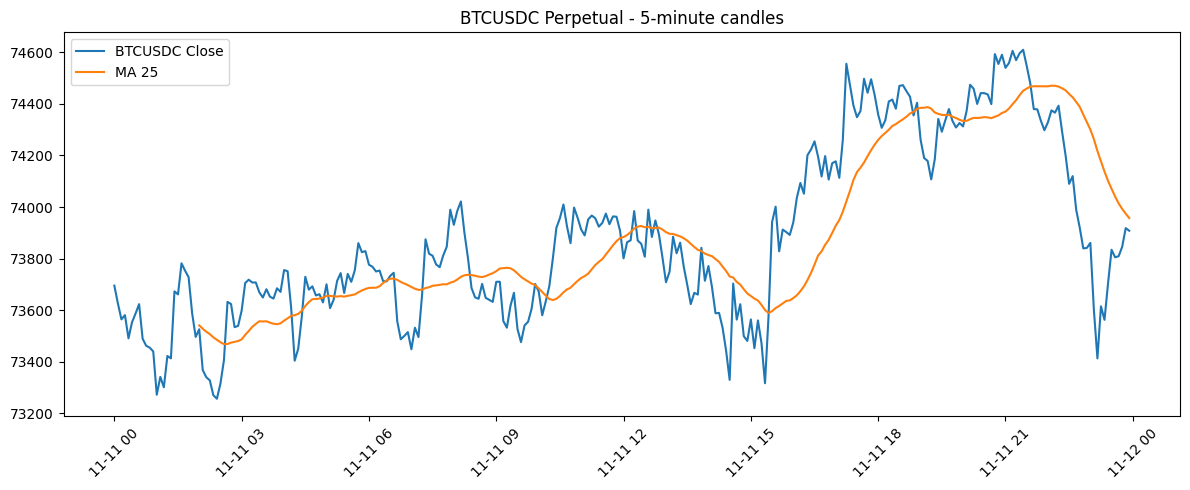

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(df["open_time"], df["close"], label="BTCUSDC Close")
plt.plot(df["open_time"], df["ma25"], label="MA 25")
plt.legend()
plt.title("BTCUSDC Perpetual - 5-minute candles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

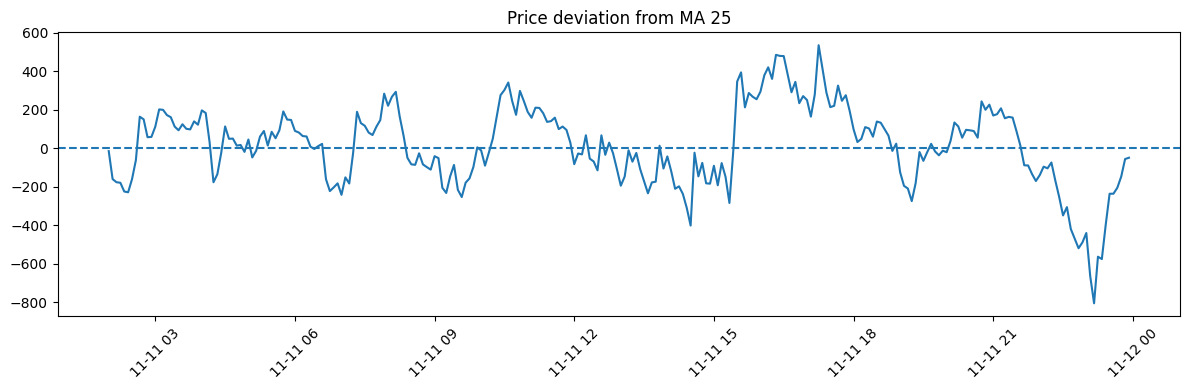

In [24]:
# Plot deviation from the moving average
plt.figure(figsize=(12, 4))
plt.plot(df["open_time"], df["deviation"])
plt.axhline(0, linestyle="--")
plt.title("Price deviation from MA 25")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Hypothesis 1: Do deviations shrink?

In [28]:
display(df.tail())

,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume,ignore,ma25,deviation,log_return,next_deviation,deviation_change
283,2026-11-11 23:35:00+00:00,73831.7,73848.2,73722.0,73805.1,123.653,2026-11-11 23:39:59.999000+00:00,9127387.8863,2470,81.323,6003759.1260,0,74040.992,-235.892,-0.000397,-204.848,-31.044
284,2026-11-11 23:40:00+00:00,73811.1,73814.8,73701.1,73809.3,66.213,2026-11-11 23:44:59.999000+00:00,4883096.9714,2168,27.648,2038993.2829,0,74014.148,-204.848,0.000057,-146.884,-57.964
285,2026-11-11 23:45:00+00:00,73814.8,73870.3,73763.5,73845.9,106.066,2026-11-11 23:49:59.999000+00:00,7829378.2155,2786,52.456,3872118.7922,0,73992.784,-146.884,0.000496,-56.056,-90.828
286,2026-11-11 23:50:00+00:00,73849.4,73994.5,73796.7,73918.3,191.526,2026-11-11 23:54:59.999000+00:00,14151675.5902,4453,79.202,5852662.3155,0,73974.356,-56.056,0.000980,-49.276,-6.780
287,2026-11-11 23:55:00+00:00,73918.4,74020.8,73900.0,73908.0,78.215,2026-11-11 23:59:59.999000+00:00,5786274.6990,2564,43.749,3236633.6066,0,73957.276,-49.276,-0.000139,NaN,NaN


In [26]:
df["next_deviation"] = df["deviation"].shift(-1)

df["deviation_change"] = df["next_deviation"].abs() - df["deviation"].abs()

valid_dev = df["deviation_change"].dropna()

print("H1: Deviation shrinkage")
print("Mean change in absolute deviation:", valid_dev.mean())
print("Fraction of shrinking deviations:", (valid_dev < 0).mean())

H1: Deviation shrinkage
Mean change in absolute deviation: 0.13009885931559068
Fraction of shrinking deviations: 0.5095057034220533


# 5. Hypothesis 2:  Do returns reverse relative to MA25?

In [29]:
df["next_return"] = df["log_return"].shift(-1)

above = df.loc[df["deviation"] > 0, "next_return"].dropna()

below = df.loc[df["deviation"] < 0, "next_return"].dropna()

print("\nH2: Next 5-minute returns")
print("Mean return when above MA25:", above.mean())
print("Mean return when below MA25:", below.mean())
print("Difference (above - below):", above.mean() - below.mean())
print("Observations above:", len(above))
print("Observations below:", len(below))


H2: Next 5-minute returns
Mean return when above MA25: -8.450054610731664e-05
Mean return when below MA25: 0.00014014695405288586
Difference (above - below): -0.0002246475001602025
Observations above: 141
Observations below: 122


# Crazy experiment


        THE NOVEMBER 11 EXPERIMENT
Training observations: 169
Unseen observations:   91

FINAL EQUITY (START = 1.0000)
BTC buy & hold:       0.9960
Simple reversal:      0.9968
Machine learning:     1.0013

DIRECTIONAL ACCURACY
Machine learning: 50.55%

RANDOMIZED BENCHMARK
Random median equity: 0.9996
ML percentile: 56.1%
Reversal percentile: 40.2%


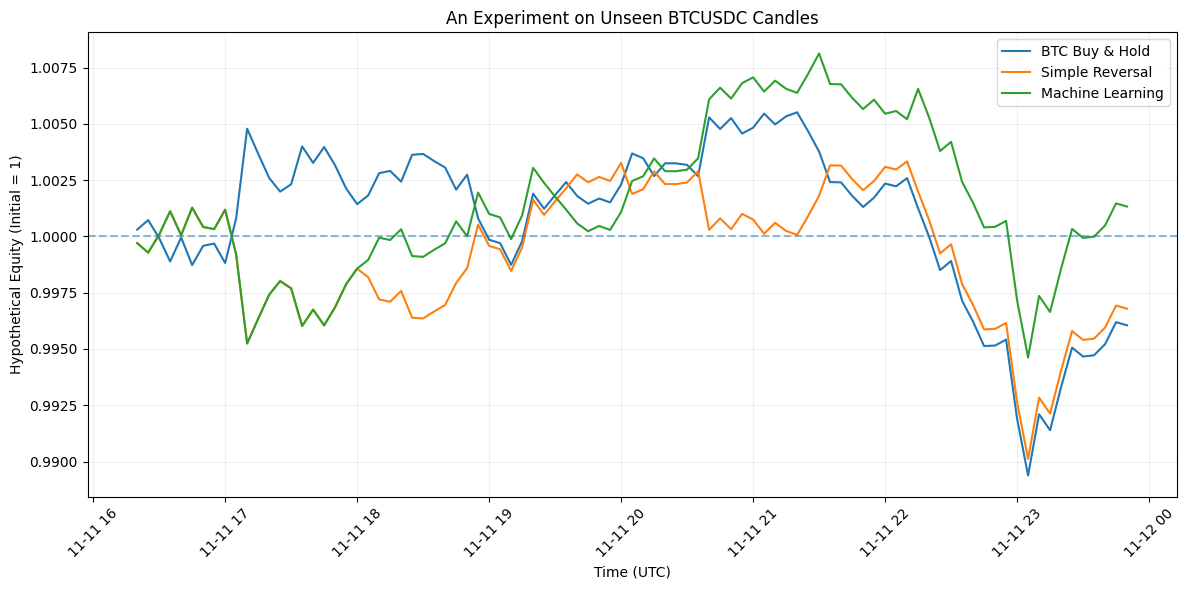

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = df.copy().sort_values("open_time")

data["distance"] = np.log(data["close"] / data["ma25"])
data["momentum"] = np.log(data["close"] / data["close"].shift(3))
data["volatility"] = data["log_return"].rolling(12).std()
data["ma_slope"] = np.log(data["ma25"] / data["ma25"].shift(3))
data["next_return"] = data["log_return"].shift(-1)

features = ["distance", "momentum", "volatility", "ma_slope"]

data = data.dropna(subset=features + ["next_return"]).copy()

split = int(len(data) * 0.65)
train = data.iloc[:split]
test = data.iloc[split:]

model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))

model.fit(train[features], train["next_return"])

test = test.copy()
test["prediction"] = model.predict(test[features])

# Two opposing forecasts
test["model_position"] = np.sign(test["prediction"])
test["simple_position"] = -np.sign(test["distance"])

test["model_return"] = test["model_position"] * test["next_return"]
test["simple_return"] = test["simple_position"] * test["next_return"]

test["model_equity"] = np.exp(test["model_return"].cumsum())
test["simple_equity"] = np.exp(test["simple_return"].cumsum())
test["btc_equity"] = np.exp(test["next_return"].cumsum())

# A randomized reference
rng = np.random.default_rng(42)
simulations = []

for _ in range(2000):
    random_positions = rng.choice([-1, 1], size=len(test))
    simulated_return = np.sum(random_positions * test["next_return"].to_numpy())
    simulations.append(np.exp(simulated_return))

simulations = np.array(simulations)

model_final = test["model_equity"].iloc[-1]
simple_final = test["simple_equity"].iloc[-1]

print("\n" + "=" * 46)
print("        THE NOVEMBER 11 EXPERIMENT")
print("=" * 46)

print(f"Training observations: {len(train)}")
print(f"Unseen observations:   {len(test)}")

print("\nFINAL EQUITY (START = 1.0000)")
print(f"BTC buy & hold:       {test['btc_equity'].iloc[-1]:.4f}")
print(f"Simple reversal:      {simple_final:.4f}")
print(f"Machine learning:     {model_final:.4f}")

print("\nDIRECTIONAL ACCURACY")
print(
    "Machine learning:",
    f"{accuracy_score(test['next_return'] > 0, test['prediction'] > 0):.2%}",
)

print("\nRANDOMIZED BENCHMARK")
print(f"Random median equity: {np.median(simulations):.4f}")
print("ML percentile:", f"{100 * np.mean(simulations < model_final):.1f}%")
print("Reversal percentile:", f"{100 * np.mean(simulations < simple_final):.1f}%")

plt.figure(figsize=(12, 6))

plt.plot(test["open_time"], test["btc_equity"], label="BTC Buy & Hold")
plt.plot(test["open_time"], test["simple_equity"], label="Simple Reversal")
plt.plot(test["open_time"], test["model_equity"], label="Machine Learning")

plt.axhline(1, linestyle="--", alpha=0.5)
plt.title("An Experiment on Unseen BTCUSDC Candles")
plt.ylabel("Hypothetical Equity (Initial = 1)")
plt.xlabel("Time (UTC)")
plt.legend()
plt.grid(alpha=0.2)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()